# Road Surface Type Classification Task

## Phase 1

### Section 1: List of requirements

This section records the software environment and package versions needed to reproduce the dataset audit, exploratory analysis, and kNN baseline on the JupyterHub VM. NumPy and pandas handle arrays and tables, Pillow handles images, and scikit-learn provides the nearest-neighbor model.

Reproduction on JupyterHub follows three steps:
1. Clone the repository and enter the project root directory.
2. Place StreetSurfaceVis under data (streetSurfaceVis_v1_0.csv and s_256).
3. Install packages in the active kernel with pip install pandas numpy opencv-python pillow scikit-learn.

The next cell records the VM and installed package versions.

In [1]:
import sys
from pathlib import Path
import pandas as pd

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.helper.inventory import get_environment_info

env_info = get_environment_info()
env_rows = [("Python", env_info["python_version"]), ("Platform", env_info["os"])]
env_rows.extend(env_info["packages"].items())
pd.DataFrame(env_rows, columns=["Component", "Version"])

,Component,Version
0,Python,3.12.6
1,Platform,Linux 5.15.0-198-generic
2,numpy,2.3.5
3,pandas,3.0.6
4,opencv-python,not installed
5,pillow,12.3.0
6,scikit-learn,1.9.1


### Section 2: Description of the dataset

Our primary objective is five-class road surface type classification. The model predicts the ground surface material visible in an input image: asphalt, concrete, paving stones, sett, or unpaved. A secondary attribute present in the dataset is surface quality, recorded across five condition levels from very bad to excellent. For our project scope, surface quality is retained purely as descriptive metadata and is excluded from the prediction targets.

The project uses StreetSurfaceVis v1.0, published on [Zenodo](https://doi.org/10.5281/zenodo.11449977) (Kapp et al., 2024). The authors collected street-level imagery in Germany through Mapillary. The release offers several image sizes based on width, not the shorter side. We use the s_256 release; most files are 256 pixels wide, with varying heights.

Metadata is provided in streetSurfaceVis_v1_0.csv, which documents nine columns: mapillary_image_id, user_id, user_name, captured_at, longitude, latitude, train, surface_type, and surface_quality. Each image file in s_256 is named after its unique ID with a .jpg extension. This establishes a 1-to-1 deterministic mapping between metadata rows and image files.

Crowdsourced images were captured by volunteer drivers, cyclists, and pedestrians using mobile devices. Consequently, the dataset exhibits substantial variability in camera pitch, mounting height, weather, and seasonal illumination. Coverage is confined to Germany. This geographic focus concentrates regional roadway patterns, such as cobblestone sett and interlocking pavers.

These visual variations introduce intra-class variance and background clutter from vehicles, roadside structures, and vegetation. The official release contains 9,122 records (Kapp, 2025). However, reliable model training requires verified readable assets. Section 3 conducts an image inventory and decode audit to identify corrupt or missing files before splitting the data.

In [2]:
import os

BASE_DATA = ROOT_DIR / "data"
METADATA_PATH = str(BASE_DATA / "streetSurfaceVis_v1_0.csv")
DATA_PATH = str(BASE_DATA / "s_256")

### Section 3: Exploratory data analysis

We check every CSV record for repeated image IDs and fully repeated rows. These counts describe different problems: an ID can recur even if its other fields differ.


In [3]:
from src.helper.inventory import load_and_validate_metadata

metadata_df, metadata_summary = load_and_validate_metadata(METADATA_PATH)
pd.DataFrame([metadata_summary]).T.rename(columns={0: "Value"})

,Value
total_records,9122
expected_total,9122
train_records,8346
expected_train,8346
test_records,776
expected_test,776
unique_ids,9122
duplicate_ids,0
fully_repeated_rows,0
has_nulls,False


We check whether each named image file exists and can be opened. Only readable files enter the byte comparison below.


In [4]:
from src.helper.inventory import audit_image_inventory

inventory_df, audit_summary, missing_ids, decode_fails, extra_files = (
    audit_image_inventory(metadata_df, DATA_PATH)
)
pd.DataFrame([audit_summary]).T.rename(columns={0: "Count"})

,Count
expected_images,9122
found_images,9122
readable_images,9120
missing_images,0
decode_failures,2
extra_files,0
unusable_images,2


We inspect the decode failures identified during the image audit, displaying their image identifiers, failure reasons, and corresponding metadata records.

In [5]:
decode_df = pd.DataFrame(
    decode_fails, columns=["mapillary_image_id", "decode_error", "file_size_bytes"]
)
metadata_df[metadata_df["mapillary_image_id"].isin(decode_df["mapillary_image_id"])].merge(
    decode_df, on="mapillary_image_id"
)

,mapillary_image_id,user_id,user_name,captured_at,longitude,latitude,train,surface_type,surface_quality,decode_error,file_size_bytes
0,3865590250223952,103078715264357,hotteliene,1583081300392,10.581377,53.325355,True,concrete,excellent,cannot identify image file '/home/jupyter-csc9...,0
1,2289217127888486,106289114939007,goobersmash,1461932090212,13.035185,52.404632,True,sett,good,cannot identify image file '/home/jupyter-csc9...,0


We check for any missing image files or extra untracked files in the image directory to ensure complete dataset alignment.

In [6]:
file_discrepancies = {
    "missing_image_ids": missing_ids,
    "extra_filenames": extra_files,
}
pd.DataFrame([file_discrepancies]).T.rename(columns={0: "Discrepancies"})

,Discrepancies
missing_image_ids,[]
extra_filenames,[]


The audit reconciles 9,122 expected records with 9,120 readable images, 2 decode failures of size 0 bytes, and 0 missing or extra files. The verified inventory dataframe is preserved for subsequent split and balance checks.

We compare the bytes of all 9,120 readable files. Matching SHA-256 digests are confirmed byte for byte. Group counts show where identical images occur in the published partitions; copies still count as separate usable records in the EDA.


In [7]:
from src.helper.inventory import audit_duplicate_images

duplicate_summary, duplicate_groups, read_failures = audit_duplicate_images(inventory_df)
assert duplicate_summary["compared_files"] + duplicate_summary["read_failures"] == inventory_df.loc[inventory_df["is_readable"], "file_path"].nunique()
pd.DataFrame([duplicate_summary]).T.rename(columns={0: "Count"})


,Count
compared_files,9120
read_failures,0
identical_file_groups,8
affected_image_ids,16
within_train_groups,8
within_test_groups,0
cross_split_groups,0
conflicting_surface_type_groups,0
conflicting_surface_quality_groups,1


Each row shows one ID, its surface type, its separate surface-quality label, and its published partition. The group number joins byte-identical files.


In [8]:
duplicate_groups[["group", "mapillary_image_id", "surface_type", "surface_quality", "train"]]

,group,mapillary_image_id,surface_type,surface_quality,train
0,1,155881879847389,paving_stones,good,True
1,1,216839193329808,paving_stones,good,True
2,2,1823349551191443,sett,bad,True
3,2,1889128151294434,sett,bad,True
4,3,255475163307416,paving_stones,intermediate,True
5,3,992905331431472,paving_stones,intermediate,True
6,4,321048266708127,sett,bad,True
7,4,956168328603371,sett,bad,True
8,5,324818063042590,sett,intermediate,True
9,5,439906807819690,sett,intermediate,True


The audit found eight pairs of byte-identical files involving 16 image IDs, all in published training. No exact duplicates crossed the published train/test split. All pairs agreed on surface type. We exclude the pair with conflicting surface-quality labels in Section 4 and keep the other pairs together.

The release has 9,122 unique IDs and no fully repeated CSV rows. Two zero-byte training files cannot be opened: concrete `3865590250223952` and sett `2289217127888486`. There are no missing or extra files. The other 9,120 images are usable. Eight byte-identical groups involve 16 IDs, all within published training. Group 8 (`529834985029767`, `690122179011682`) has sett as its surface type on both records; only their surface-quality labels disagree.


#### Surface-type balance

The table compares published release records with readable images. Each percentage uses the readable total for its own partition. Identical files count as separate records here. Section 4 applies the agreed exclusions before generating the splits.

In [9]:
partitions = {
    "all": inventory_df,
    "train": inventory_df.loc[inventory_df["train"]],
    "test": inventory_df.loc[~inventory_df["train"]],
}
balance_rows = []
for partition, records in partitions.items():
    usable_total = int(records["is_readable"].sum())
    for surface_type, group in records.groupby("surface_type", sort=True):
        usable_count = int(group["is_readable"].sum())
        balance_rows.append({
            "partition": partition, "surface_type": surface_type,
            "release records": len(group), "usable images": usable_count,
            "usable %": round(100 * usable_count / usable_total, 1),
        })
balance = pd.DataFrame(balance_rows)
assert balance.groupby("partition")["usable images"].sum().to_dict() == {"all": 9120, "train": 8344, "test": 776}
balance

,partition,surface_type,release records,usable images,usable %
0,all,asphalt,3734,3734,40.9
1,all,concrete,972,971,10.6
2,all,paving_stones,2037,2037,22.3
3,all,sett,1363,1362,14.9
4,all,unpaved,1016,1016,11.1
5,train,asphalt,3204,3204,38.4
6,train,concrete,956,955,11.4
7,train,paving_stones,1924,1924,23.1
8,train,sett,1331,1330,15.9
9,train,unpaved,931,931,11.2


Asphalt is the largest class: 3,734 of 9,120 usable images (40.9%). Concrete has 971 (10.6%). The published test set has only 16 concrete and 32 sett images, so results for those classes may vary substantially with a few mistakes. The two unreadable records account for the only release-to-usable differences.


#### Training examples

The next figure uses two fixed, readable training IDs for each surface type. The published labels stay as given. These ten images illustrate possible confusion.


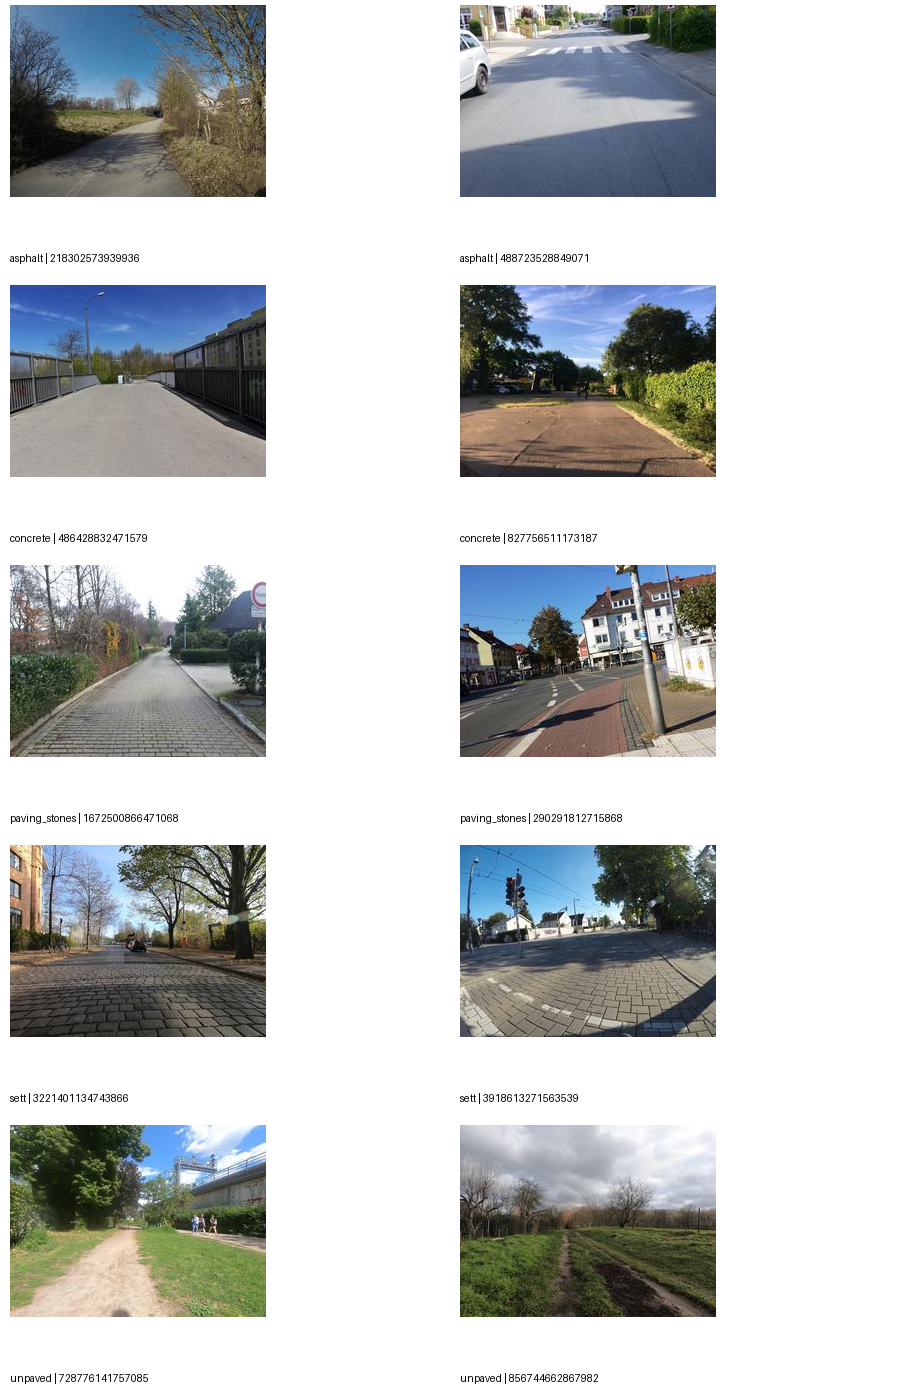

In [10]:
from PIL import Image
from IPython.display import display
from src.helper.figures import training_examples_figure

example_ids = {
    "asphalt": ["218302573939936", "488723528849071"],
    "concrete": ["486428832471579", "827756511173187"],
    "paving_stones": ["1672500866471068", "290291812715868"],
    "sett": ["3221401134743866", "3918613271563539"],
    "unpaved": ["728776141757085", "856744662867982"],
}
display(training_examples_figure(inventory_df, example_ids))

The smooth asphalt example can resemble the smooth concrete example. Paving stones and sett both show repeated blocks; the chosen sett example with square blocks is especially easy to confuse with paving stones. The unpaved examples range from a dry path to a muddy track. Surface quality describes condition and does not change the surface-type target.


#### Image dimensions

We open each usable image and record its width and height in pixels. The summary covers the same 9,120 records as the balance table, including every member of an identical-image group.


In [11]:
usable_images = inventory_df.loc[inventory_df["is_readable"]].copy()
dimensions = []
for image_path in usable_images["file_path"]:
    with Image.open(image_path) as image:
        dimensions.append(image.size)
usable_images[["width", "height"]] = dimensions
assert len(usable_images) == len(dimensions) == 9120
usable_images[["width", "height"]].describe(percentiles=[0.05, 0.5, 0.95]).round(1)

,width,height
count,9120.0,9120.0
mean,255.8,181.0
std,4.6,23.9
min,81.0,110.0
5%,255.0,144.0
50%,256.0,192.0
95%,256.0,192.0
max,256.0,458.0


The next table shows the ten most common width and height combinations. It helps distinguish the dominant image sizes from the unusual extremes in the summary.


In [12]:
usable_images.groupby(["width", "height"]).size().nlargest(10).rename("images")

width  height
256    192       6644
       144       1754
254    143        184
255    144        127
256    224         61
255    192         48
       170         44
256    115         43
       191         42
       193         26
Name: images, dtype: int64

Most files are 256 pixels wide. The common sizes are 256 × 192 (6,644 images) and 256 × 144 (1,754 images); a few have unusual proportions. Section 5 crops the lower-center road region, preserves its aspect ratio, and pads it to a 128 × 96 canvas. The canvas is our practical shared-input choice; these dimension counts do not establish an optimal model input size.

### Section 4: Dataset split

We preserve the published test assignment and divide the remaining images into training and validation sets. The exclusions are two unreadable images and the two images in the duplicate pair with conflicting surface-quality labels. This leaves 9,118 included records. Groups 1 to 7 retain both copies within the same split.

Exact byte matching cannot detect different photos of the same road. The release has no road or sequence IDs for stronger grouping. Our checks establish separation of exact duplicates, not independence of every road view.

The next cell filters the inventory, generates the splits, verifies them, and saves the assignments to `data/splits.csv`. It uses seed 42 and a 0.78 training share of the 8,342 included records in published training. The remaining 22% goes to validation by surface type, keeping duplicate groups together. The result is 6,507 training, 1,835 validation, and 776 test images: 71.36%, 20.13%, and 8.51% overall. This approximates the intended 70/20/10 allocation while preserving the published test set.

In [13]:
from src.helper.dataset_split import (
    filter_usable_dataset,
    generate_dataset_splits,
    verify_dataset_splits,
    save_split_assignments,
)

usable_df, exclusions = filter_usable_dataset(inventory_df, duplicate_groups)
split_df = generate_dataset_splits(
    usable_df=usable_df,
    duplicate_groups=duplicate_groups,
    train_val_ratio=0.78,
    random_state=42,
)
verification = verify_dataset_splits(split_df, duplicate_groups)
splits_csv = save_split_assignments(split_df, str(BASE_DATA / "splits.csv"))

print(f"Usable: {len(usable_df):,} | Excluded: {exclusions['total_excluded']}")
print(f"Splits: {verification['split_counts']}")
print(f"Proportions (%): {verification['split_proportions_pct']}")
display(verification["type_distribution"])

Usable: 9,118 | Excluded: 4
Splits: {'train': 6507, 'val': 1835, 'test': 776}
Proportions (%): {'train': 71.36, 'val': 20.13, 'test': 8.51}


split,test,train,val,All
surface_type,,,,
asphalt,530,2499,705,3734
concrete,16,745,210,971
paving_stones,113,1501,423,2037
sett,32,1036,292,1360
unpaved,85,726,205,1016
All,776,6507,1835,9118


The verifier checks disjoint image IDs, preserved published test membership, exact-duplicate separation, and complete coverage. We save the verified assignments by image ID so every model can use the same split. Validation supports model selection and fit assessment. Test outcomes stay out of choices about inputs, model families, hyperparameters, and training duration. Any later learned preprocessing fits on training data alone and applies unchanged to validation and test.

### Section 5: Traditional ML model training

#### Shared RGB inputs

The [StreetSurfaceVis Usage Notes](https://www.nature.com/articles/s41597-024-04295-9#Sec11) recommend cropping because annotations describe the road at the bottom center. We keep the central half of the width and bottom half of the height: crop bounds are `(0.25 × width, 0.50 × height, 0.75 × width, height)`. This provides annotation-based support for our input treatment. We have not tested whether cropping improves our models over full images.

[SurfaceAI](https://arxiv.org/html/2409.18922v1#S2.SS2) fine-tunes EfficientNetV2-S using StreetSurfaceVis’s 9,122 annotated images. It is a separate system paper by the dataset authors. Its [released configuration](https://github.com/SurfaceAI/classification_models/blob/8273a6779d17c95eb9ef0437fedd83535db0a603/experiments/config/global_config.py#L36) specifies the lower-middle-half crop and 384 × 384 resizing. The [system preprocessing code](https://github.com/SurfaceAI/road_network_classification/blob/0d26a3160d90658974c82af14940623c61e7eb0a/src/modules/Models.py#L46) confirms crop-before-resize. Those exact settings come from code; the paper does not specify them. They provide precedent, not evidence that our canvas is optimal.

Our crop fits inside a 128 × 96 black canvas without stretching. A 256 × 192 image yields a 128 × 96 crop. A 256 × 144 image yields a 128 × 72 crop with 12 black rows above and below. This smaller canvas suits the selected release and keeps the shared pixel vector manageable. Crop coordinates use Python’s nearest-integer rounding, with exact halves rounded to even. Pillow’s `ImageOps.contain` uses Lanczos resampling; integer-centered padding assigns an odd spare pixel to the bottom or right.

The next figure shows two included training images beside their prepared versions, one for each common source size. Padding stays visible in the prepared image. Test images do not guide this illustration.

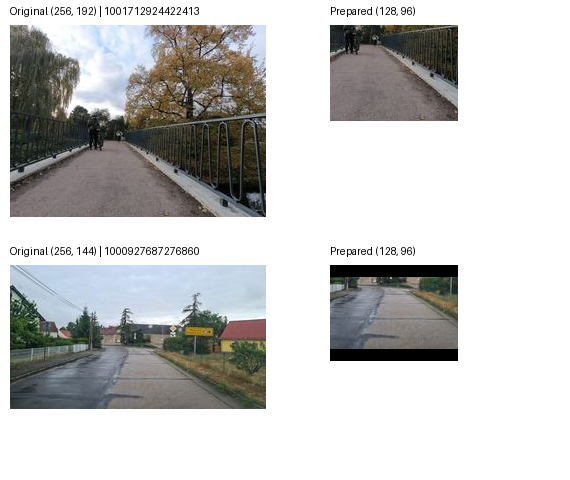

In [14]:
import numpy as np
from src.helper.shared_inputs import prepare_split, SURFACE_TYPES, LABEL_IDS, SEED
from src.helper.figures import crop_comparison_figure

comparison_sizes = [(256, 192), (256, 144)]
display(crop_comparison_figure(split_df, comparison_sizes))

Every prepared image has height 96, width 128, and three channels in red, green, blue (RGB) order. Dividing each 8-bit channel value by 255.0 gives float32 values from zero to one; this constant scaling needs no fitted statistics. Flattening reads rows left to right, with RGB channels changing fastest, yielding 36,864 features. Metadata never enters this vector. Traditional models use `flat`; neural models can reshape the same pixels. There are no random augmentations or learned features.

The next cell prepares each saved split in row order and keeps its image IDs and encoded surface-type labels beside the pixels. Missing or unreadable inputs fail clearly instead of reducing the dataset. The flattened array shares memory with the image array, so both views contain the same values. The table records shapes and class IDs for downstream model tasks.

In [15]:
shared = {
    name: prepare_split(split_df.loc[split_df["split"] == name], DATA_PATH)
    for name in ("train", "val", "test")
}
feature_summary = []
for name, data in shared.items():
    assert np.isfinite(data["images"]).all()
    assert 0 <= data["images"].min() <= data["images"].max() <= 1
    assert np.shares_memory(data["images"], data["flat"])
    feature_summary.append({"split": name, "images": data["images"].shape,
                            "flat": data["flat"].shape, "labels": data["labels"].shape})
display(pd.DataFrame(feature_summary))
display(pd.Series(LABEL_IDS, name="class ID").rename_axis("surface type"))

,split,images,flat,labels
0,train,"(6507, 96, 128, 3)","(6507, 36864)","(6507,)"
1,val,"(1835, 96, 128, 3)","(1835, 36864)","(1835,)"
2,test,"(776, 96, 128, 3)","(776, 36864)","(776,)"


surface type
asphalt          0
concrete         1
paving_stones    2
sett             3
unpaved          4
Name: class ID, dtype: int64

#### Selection and reporting protocol

Define a small ordered grid of candidate settings before each search. Fit every candidate on training data alone and evaluate it on the saved validation set. Use seed 42 for stochastic operations where supported. Record candidate values, complete model settings, package versions, and execution environment. Explain learning rate and schedule where applicable, or why they do not apply. Literature can justify the candidates; our validation results choose the winner. Cross-validation is not required for this protocol.

Select the highest unrounded validation macro-F1. F1 combines precision (how often a predicted class is correct) and recall (how many actual examples of that class are found). Macro-F1 averages F1 equally across all five surface types. An exact tie uses higher validation accuracy, the fraction of correct predictions. If both scores tie exactly, keep the earlier candidate in declared grid order. `rank_candidates` implements that ordering and returns only the top five configurations. Round scores only for display.

`evaluate_predictions` uses scikit-learn metrics to return accuracy, macro-F1, per-class precision, recall, F1, and support (actual sample count). Its confusion matrix has actual surface types in rows and predictions in columns. All reports use asphalt, concrete, paving_stones, sett, and unpaved in that order, encoded 0 through 4. Undefined per-class scores are zero; macro-F1 always includes five classes. The next cell exposes the common reporting functions and records the seed without fitting a model.

In [16]:
from src.helper.shared_inputs import evaluate_predictions, rank_candidates

print(f"Search seed: {SEED}")
print("Selection: validation macro-F1, validation accuracy, declared candidate order")
print("Reports: accuracy, macro-F1, per-class precision/recall/F1/support, confusion matrix")


Search seed: 42
Selection: validation macro-F1, validation accuracy, declared candidate order
Reports: accuracy, macro-F1, per-class precision/recall/F1/support, confusion matrix


Complete selection before evaluating the chosen configuration on test data. Do not refit on training plus validation. Compare the selected model’s training and validation accuracy and macro-F1 to assess fit. For the neural network, also record training and validation loss across training. Discuss observed gaps and curves without a universal overfitting threshold or an unsupported diagnosis from low scores alone. The test set has only 16 concrete images, so explain that class’s scores alongside its sample count.

#### k-nearest neighbors baseline

For each image, k-nearest neighbors (kNN) finds the k closest training images and predicts their most common surface type. We use the shared normalized RGB pixels unchanged, Euclidean distance (straight-line distance between pixel vectors), brute-force search, and one vote per neighbor. There is no second scaling step. The [scikit-learn classifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html) stores training examples; it has no learning rate, schedule, epochs, or gradient-based optimization.

We declare every integer k from 1 through 20 in ascending order. The helper retrieves 20 neighbors per validation image once, then reuses their labels for all candidates. A tied class vote selects the lowest class ID. Equal-distance ordering follows scikit-learn and the preserved training-row order. The next cell checks the prepared IDs and labels against the saved assignments and confirms the expected split sizes before fitting.

The vote table has one row per validation image and five columns, one per surface type. At each k, we add one vote for the next neighbor's label. For neighbor labels `[2, 0, 2]`, predictions at k = 1, 2, and 3 are `[2, 0, 2]`: the second step ties classes 0 and 2, so class 0 wins. NumPy's `argmax` selects the first largest count. Earlier votes remain in the table as k increases.

In [17]:
from src.helper.knn import K_VALUES, tune_knn

saved_assignments = pd.read_csv(BASE_DATA / "splits.csv", dtype={"mapillary_image_id": str})
assert {name: len(data["labels"]) for name, data in shared.items()} == {
    "train": 6507, "val": 1835, "test": 776
}
for name, data in shared.items():
    assigned = saved_assignments.loc[saved_assignments["split"] == name]
    np.testing.assert_array_equal(data["image_ids"], assigned["mapillary_image_id"])
    np.testing.assert_array_equal(data["labels"], assigned["surface_type"].map(LABEL_IDS))
    assert data["flat"].shape == (len(assigned), 36864)
    assert data["flat"].dtype == np.float32
print(f"Declared search: k = {list(K_VALUES)}; saved split IDs and labels match.")

Declared search: k = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]; saved split IDs and labels match.


The search fits only the original training set. Validation macro-F1 determines the winner, then accuracy and ascending k resolve exact ties. All 20 candidate results stay in memory; only the top five score rows appear below. The timer separates the validation neighbor query from total tuning, which also includes fitting, voting, and scoring. Both exclude the earlier image preparation. The settings table records every classifier parameter after selection.

In [18]:
knn_search = tune_knn(
    shared["train"]["flat"], shared["train"]["labels"],
    shared["val"]["flat"], shared["val"]["labels"],
)
assert len(knn_search["candidates"]) == 20
knn_model = knn_search["model"]
knn_selected = knn_search["top_five"][0]
knn_top_five = pd.DataFrame([
    {key: row[key] for key in ("k", "validation_macro_f1", "validation_accuracy")}
    for row in knn_search["top_five"]
])
display(knn_top_five.round(4))
display(pd.Series(knn_model.get_params(), name="value").to_frame())
display(pd.Series({
    "validation neighbor search (seconds)": knn_search["validation_search_seconds"],
    "total tuning (seconds)": knn_search["tuning_seconds"],
}, name="VM runtime").round(3).to_frame())
print(f"Selected k: {knn_selected['k']}; original training rows: {knn_model.n_samples_fit_}")

,k,validation_macro_f1,validation_accuracy
0,1,0.2950,0.3717
1,3,0.2665,0.3962
2,9,0.2595,0.4109
3,4,0.2582,0.3853
4,5,0.2551,0.3886


,value
algorithm,brute
leaf_size,30
metric,euclidean
metric_params,None
n_jobs,1
n_neighbors,1
p,2
weights,uniform


,VM runtime
validation neighbor search (seconds),47.618
total tuning (seconds),48.995


Selected k: 1; original training rows: 6507


The search selected k = 1: validation macro-F1 was 0.2950 and accuracy was 37.17%. k = 3 had higher accuracy (39.62%) but lower macro-F1 (0.2665), so it ranked second under our declared rule. Giving each class equal weight changes which configuration wins. The validation neighbor query took 47.618 seconds; total tuning took 48.995 seconds, excluding preprocessing. These measurements establish a completed baseline run, with modest validation performance and a noticeable distance-search cost.

We query the training images explicitly and reuse the selected validation predictions for a fit comparison. Each training image can be its own neighbor, so training scores are optimistic, especially at k = 1. The table reports accuracy and macro-F1 for the same fitted model on both splits; the gaps help describe how its apparent training fit transfers to unseen validation images. kNN has no epoch-loss curve.

In [19]:
from time import perf_counter

knn_training_started = perf_counter()
knn_train_predictions = knn_model.predict(shared["train"]["flat"])
knn_training_seconds = perf_counter() - knn_training_started
knn_train_report = evaluate_predictions(shared["train"]["labels"], knn_train_predictions)
knn_validation_report = evaluate_predictions(
    shared["val"]["labels"], knn_selected["predictions"]
)
knn_fit_scores = pd.DataFrame({
    name: {metric: report[metric] for metric in ("accuracy", "macro_f1")}
    for name, report in (("training", knn_train_report), ("validation", knn_validation_report))
}).T
display(knn_fit_scores.round(4))
display((knn_fit_scores.loc["training"] - knn_fit_scores.loc["validation"])
        .rename("training minus validation").round(4).to_frame())
print(f"Training prediction time: {knn_training_seconds:.3f} seconds")

,accuracy,macro_f1
training,1.0000,1.000
validation,0.3717,0.295


,training minus validation
accuracy,0.6283
macro_f1,0.7050


Training prediction time: 138.310 seconds


At k = 1, training accuracy and macro-F1 were both 1.0000, while validation accuracy was 0.3717 and macro-F1 was 0.2950. Training exceeded validation by 62.83 percentage points in accuracy and 0.7050 in macro-F1. The explicit training queries can retrieve themselves, explaining the optimistic perfect score. This large observed gap shows that apparent training fit transfers poorly to validation. The scores alone do not identify whether pixel features, noise, or other dataset properties explain the errors.

The selected k is now fixed. We query test pixels once with that configuration and keep the original training set. The next reports use the common five-class definitions: overall accuracy and macro-F1, each class's precision, recall, F1 and support, then a confusion matrix with actual classes in rows. Test prediction time measures the final query and voting, excluding preprocessing and tuning. Test results do not enter selection.

In [20]:
assert knn_model.n_samples_fit_ == len(shared["train"]["labels"])
knn_test_started = perf_counter()
knn_test_predictions = knn_model.predict(shared["test"]["flat"])
knn_test_seconds = perf_counter() - knn_test_started
knn_test_report = evaluate_predictions(shared["test"]["labels"], knn_test_predictions)
display(pd.Series({metric: knn_test_report[metric] for metric in ("accuracy", "macro_f1")},
                  name="test score").round(4).to_frame())
display(knn_test_report["per_class"].round(4))
display(knn_test_report["confusion_matrix"])
assert knn_test_report["per_class"].loc["concrete", "support"] == 16
print(f"Test prediction time: {knn_test_seconds:.3f} seconds for {len(knn_test_predictions)} images")

,test score
accuracy,0.4394
macro_f1,0.2360


,precision,recall,f1,support
asphalt,0.7759,0.5226,0.6246,530
concrete,0.0233,0.1250,0.0392,16
paving_stones,0.1955,0.3805,0.2583,113
sett,0.0238,0.0312,0.0270,32
unpaved,0.2535,0.2118,0.2308,85


predicted,asphalt,concrete,paving_stones,sett,unpaved
actual,,,,,
asphalt,277,50,135,28,40
concrete,4,2,7,2,1
paving_stones,41,18,43,4,7
sett,10,2,14,1,5
unpaved,25,14,21,7,18


Test prediction time: 27.652 seconds for 776 images


Test accuracy was 43.94%, while macro-F1 was 0.2360. Asphalt had the highest F1 (0.6246) and 530 of 776 test images; every other class had F1 at or below 0.2583. Concrete recall was 2/16 (12.5%) with F1 0.0392. Sett recall was 1/32 (3.13%); 14 sett images were predicted as paving stones. The baseline struggles across the smaller classes, despite its higher overall accuracy. These held-out results describe the selected configuration and do not change its settings.

Training prediction took 138.310 seconds for 6,507 images; test prediction took 27.652 seconds for 776 images. These costs exclude image preparation. Raw-pixel distance compares 36,864 values per image pair, and lighting, padding, or colors can influence neighbors even when surfaces differ. The measured quality makes this a weak reference for the later neural-network comparison. No runtime or accuracy acceptance target was set. Concrete has only 16 test images, so one changed prediction moves recall by 6.25 percentage points. Class support limits how confidently we interpret these scores.

#### Neural-network experiments

The neural-network task will define its architecture, candidate settings, and training schedule. It must consume the same prepared pixels, image IDs, and labels, and record training and validation loss. Any required channel-axis rearrangement must preserve those values.